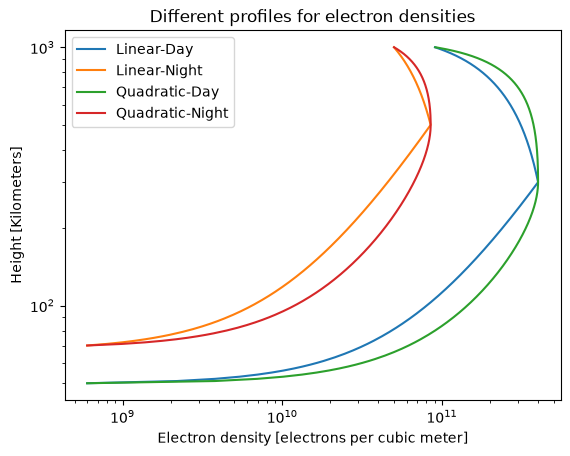

At km  0 ref index is:  1.0
At km  1 ref index is:  1.0
At km  2 ref index is:  1.0
At km  3 ref index is:  1.0
At km  4 ref index is:  1.0
At km  5 ref index is:  1.0
At km  6 ref index is:  1.0
At km  7 ref index is:  1.0
At km  8 ref index is:  1.0
At km  9 ref index is:  1.0
At km  10 ref index is:  1.0
At km  11 ref index is:  1.0
At km  12 ref index is:  1.0
At km  13 ref index is:  1.0
At km  14 ref index is:  1.0
At km  15 ref index is:  1.0
At km  16 ref index is:  1.0
At km  17 ref index is:  1.0
At km  18 ref index is:  1.0
At km  19 ref index is:  1.0
At km  20 ref index is:  1.0
At km  21 ref index is:  1.0
At km  22 ref index is:  1.0
At km  23 ref index is:  1.0
At km  24 ref index is:  1.0
At km  25 ref index is:  1.0
At km  26 ref index is:  1.0
At km  27 ref index is:  1.0
At km  28 ref index is:  1.0
At km  29 ref index is:  1.0
At km  30 ref index is:  1.0
At km  31 ref index is:  1.0
At km  32 ref index is:  1.0
At km  33 ref index is:  1.0
At km  34 ref index is: 

 60


Position of ray:  [np.float64(0.25000000000039013), np.float64(6370.433012701892)]
Position of ray:  [np.float64(0.500000000000854), np.float64(6370.866025403784)]
Position of ray:  [np.float64(0.7500000000009153), np.float64(6371.299038105676)]
Position of ray:  [np.float64(1.0000000000011344), np.float64(6371.732050807568)]
Position of ray:  [np.float64(1.2500000000004987), np.float64(6372.165063509461)]
Position of ray:  [np.float64(1.500000000000667), np.float64(6372.598076211353)]
Position of ray:  [np.float64(1.7500000000003086), np.float64(6373.031088913245)]
Position of ray:  [np.float64(2.0000000000007643), np.float64(6373.464101615137)]
Position of ray:  [np.float64(2.250000000000384), np.float64(6373.897114317029)]
Position of ray:  [np.float64(2.50000000000019), np.float64(6374.330127018921)]
Position of ray:  [np.float64(2.7499999999996287), np.float64(6374.763139720813)]
Position of ray:  [np.float64(2.9999999999994014), np.float64(6375.196152422705)]
Position of ray:  [n

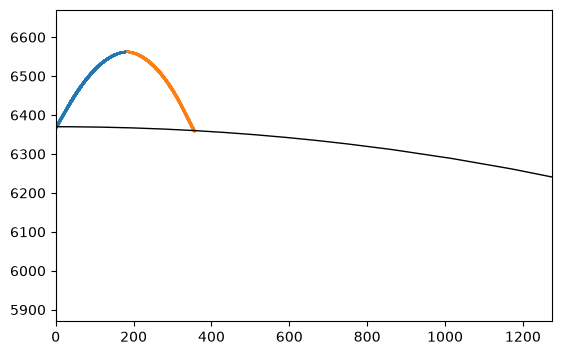

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patch
import scipy.optimize as optimize


#Import function to obtain electron density:
#Doesn't work
#from ipynb.fs.full.Refraction_index_from_electron_density import ref_index

%run "01_ionosphere_refractive_index.ipynb"

freq = 5e6# Radiofrequency from 50 kHz to 300 GHz
n=ref_index(freq,elec_dens_linear_day)


#And the grid distance:
delta_y=1 # in km

#We select the velocity of the light:
c=1 

# NOW WE NEED TO DO ITERATIONS FOR DIFFERENT FREQUANCIES TO REACH THE END POINT:

destiny=1000 #The x position we want to reach

def GetRayPolar(theta0,n):
    c = 1
    delta_r = 1
    
    #The radius of the earth:
    R_Earth=6370 # in Km
    # initial angle, our initial point is in the "top" of the earth
    phi = np.pi/2 
    #We choose the initial position of the ray:
    
    # Getting the coordinates in (r,phi) polar coordinates
    # Should be easier
    ray=[[R_Earth , phi]]
    
    #We just do iterations:
    step_t=0.5 #constant, time passing between iterations
    current_index=0 #To see in which pixel we are
    sum_r=0 #The sum of the distance from the centre, to see if it passes to the next cell

    #We track te iterations number too:
    i=1

    #A boolean to stop the iterations:
    boolean=True
    
    # Angle of rotation of each step of the Snell law
    ubre = np.pi/2 - phi #Can be negative(don't know)

    while boolean: 
        if current_index < 0:
            print("Ray returned below the modeled region.")
            break

        if current_index >= len(n):
            print("Ray escaped the modeled ionosphere.")
            break

        
        #The n index depends on the height:
        n0=n[current_index]

        if n0 <=0:
            print("Wave reached a non-propagating region.")
            break
            
        x0=step_t*(c/n0)*np.cos(theta0)
        y0=step_t*(c/n0)*np.sin(theta0)
        
        # Ray angle coordinate
        x = x0 * np.cos(ubre) - y0*np.sin(ubre)
        y = x0 * np.sin(ubre) + y0*np.cos(ubre)
        
        #We need to see if we have reached the next height with this last step
        #To do so, we check if the sum is bigger than the grid size:
        

        mod_r0 =ray[i-1][0]
        angle_0=ray[i-1][1]
        # Vector coordinates
        r1 = [mod_r0*np.cos(angle_0) + x, mod_r0*np.sin(angle_0)  + y] 
        print("Position of ray: ",r1)
        #print("r1: ",r1)
        mod_r1 = np.sqrt(r1[0]**2 + r1[1]**2)
        if(n0==0):
            print("Error: n0 is equal to zero")
            boolean=False
            break
        # print("PREVIOUS sum of height: ",sum_h0)
        if abs(sum_r + (mod_r1 - mod_r0)) >= delta_r:
            k=1
            while(abs(sum_r+(mod_r1 - mod_r0)-k*delta_r)>delta_r):
                k+=1
            n1=np.mean(n[current_index+1:current_index+k+1])
            # print("n1: ",n1)
            current_index+=k #We go to the next grid
            if current_index >= len(n):
                print("Ray escaped the modeled ionosphere.")
                break
            
            #See if changes refraction index:
            if (n1==n0):
                # print("n1 is equal to n0")
                #r2=np.sqrt((ray[i-1][0]+x)**2+(ray[i-1][1]+y)**2) #Distance from centre of earth to new point
                #r1=np.sqrt((ray[i-1][0])**2+(ray[i-1][1])**2) #Distance from centre of earth to previous point
                sum_r=sum_r+ (mod_r1-mod_r0) - k*delta_r #Goes to next cell normal
                phi=np.arctan2(r1[1],r1[0])
                #print("Iteracion n1==n0: ",i)
               
                #There is no need for rotation because theta is still expressed in previous axis
                #ubre=np.pi/2-phi
                
                ray.append([mod_r1,phi])
    
            else:
                #Snell law to calculate new angle.
                #CAUTION: Snell angle is taken from the normal and ours is from the horizontal axis:
                
                alpha0=np.pi/2-theta0
                #CAREFUL: arcsin input has to be between -1 and 1. If it exceedes, add/substract 1
                if (n1==0 or abs((n0*np.sin(alpha0))/n1)>=1):
                    #There has been an internal reflection, the wave can't pass. We stop
                    boolean=False
                else:
                    alpha=np.arcsin((n0*np.sin(alpha0))/n1)
                    theta=np.pi/2-alpha
                    # We divide the total step into 2:
                    
                    y0=delta_r-sum_r
                    x0=y0/np.tan(theta0)
                    
                    y1=c/n1*np.sin(theta)*(step_t-(c/n0)*y0/np.sin(theta0))
                    x1=y1/np.tan(theta0)
                    
                    sum_r=y1
                    
                    #Now rotate each of them manualy:
                    x_prev0=ray[i-1][0]*np.cos(ray[i-1][1])
                    y_prev0=ray[i-1][0]*np.sin(ray[i-1][1])
                    phi_0=np.arctan2(y_prev0,x_prev0)
                    ubre_0=np.pi/2-phi_0
                    
                    x0_rot = x0 * np.cos(ubre_0) - y0*np.sin(ubre_0)
                    y0_rot = x0 * np.sin(ubre_0) + y0*np.cos(ubre_0)
                    
                    # To do the next rotation we need to find the position after first step:
                    x_step0=x_prev0+x0_rot
                    y_step0=y_prev0+y0_rot
                    
                    phi_1=np.arctan2(y_step0,x_step0)
                    ubre_1=np.pi/2-phi_1
                    
                    #We add this little step to our ray, for resolution purposes:
                    r_step0=np.sqrt(x_step0**2+y_step0**2)
                    ray.append([r_step0,phi_1])
                    
                    #We need to add 1 more iteration to compensate this extra point:
                    i+=1
                    
                    x1_rot = x1 * np.cos(ubre_1) - y1*np.sin(ubre_1)
                    y1_rot = x1 * np.sin(ubre_1) + y1*np.cos(ubre_1)
                    
                    #finally, we need the final angle of the ray
                    #To know the rotation of the next points:
                    
                    x_step1=x_step0+x1_rot
                    y_step1=y_step0+y1_rot
                    
                    phi_fin=np.arctan2(y_step1,x_step1)
                    r_fin=np.sqrt(x_step1**2+y_step1**2)
                    ray.append([r_fin,phi_fin])
                    
                    #For next iterations, the rotation will be given by the angle of the last point:
                    ubre=np.pi/2-phi_fin
                    
                    #The new theta will be the last one:
                    theta0=theta
                    
            
        else:
            #If it doesn't jump to next cell the ray will travel normally:
            # The quantity that advance is the difference of r1 and r0
            #print("Iteracion fuera: ",i)
            # The angle is the one of the advanced ray
            phi=np.arctan2(r1[1],r1[0])
            ray.append([mod_r1, phi])
            sum_r+=(mod_r1-mod_r0)

            #There is no need for rotation because theta is still expressed in previous axis
            #ubre=np.pi/2-phi
            
        #Next iteration:
        i+=1
        # print(boolean)
    return ray



print("What angle do you wants?")
angle=float(input())
ray=GetRayPolar((angle*np.pi/180),n)

#Draw a circle:


figure, axes = plt.subplots()

x_axis=[]
y_axis=[]
for j in range(len(ray)):
    r = ray[j][0]
    phi = ray[j][1]
    x_axis.append(r*np.cos(phi))
    y_axis.append(r*np.sin(phi))

axes.scatter(x_axis,y_axis,s=1)

#NOW WE NEED TO COMPUTE ANDRES:
andres=[]
#The radius will be inverted and for the angles we need to mirror around the angle difference:

x_axis2=[]
y_axis2=[]


for j in range(len(ray)):
    r_Andres=ray[len(ray)-1-j][0]
    phi_Andres=ray[-1][1]-(ray[len(ray)-1-j][1]-ray[-1][1])
    # print("Angulo: ",phi_Andres*180/np.pi)
    andres.append([r_Andres,phi_Andres])
    x_axis2.append(r_Andres*np.cos(phi_Andres))
    y_axis2.append(r_Andres*np.sin(phi_Andres))
#print(y_axis2)
axes.scatter(x_axis2,y_axis2,s=1)

ray2=GetRayPolar((angle*np.pi/180),n)

x_axis3=[]
y_axis3=[]
for j in range(len(ray2)):
    x_axis3.append(ray2[0])
    y_axis3.append(ray2[1])

#print(y_axis3)
#axes.scatter(x_axis3,y_axis3,s=1)

#The radius of the earth:
R_Earth=6370
axes.set_xlim(0,R_Earth/5)
axes.set_ylim(R_Earth-500,R_Earth+300)
axes.set_aspect( 1 )
circ=patch.Circle((0,0),R_Earth,fill=False) #A circle centered at (0,0) with radius 100
axes.add_artist( circ )
#plt.title( 'Circle' )
plt.show()
